# Project overview and the camera pipeline · Yyug
**Project 24 · Activity Recognition System · Review 2.** Run the cells top to bottom (Jupyter: kernel *har*; Colab: run the setup cell first, it fetches the data and models).

In [1]:
import os, sys, subprocess, pathlib, urllib.request, zipfile, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not os.path.exists("/content/activity-recognition"):
        subprocess.run(["git", "clone", "-q", "https://github.com/rajyyug1132/activity-recognition", "/content/activity-recognition"], check=True)
    os.chdir("/content/activity-recognition")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mediapipe", "scikit-learn==1.9.1"], check=True)
    os.makedirs("data/uci", exist_ok=True); os.makedirs("models", exist_ok=True)
    if not os.path.exists("data/uci/UCI HAR Dataset"):
        urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip", "data/uci/har.zip")
        zipfile.ZipFile("data/uci/har.zip").extractall("data/uci")
        zipfile.ZipFile("data/uci/UCI HAR Dataset.zip").extractall("data/uci")
    if not os.path.exists("models/pose_landmarker_full.task"):
        urllib.request.urlretrieve("https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task", "models/pose_landmarker_full.task")
    from google.colab import drive
    drive.mount("/content/drive")
    for f in ["cnn_uci.keras", "video_rf.joblib"]:
        if os.path.exists(f"/content/drive/MyDrive/{f}"):
            subprocess.run(["cp", f"/content/drive/MyDrive/{f}", f"models/{f}"], check=True)
elif pathlib.Path.cwd().name == "notebooks":
    os.chdir("..")                      # run from the repository root

sys.path.insert(0, "src")
for f in ["config/config.yaml", "app/demo/uci_test_person_12.csv", "data/uci/UCI HAR Dataset",
          "models/cnn_uci.keras", "models/video_rf.joblib", "models/pose_landmarker_full.task"]:
    print("found  " if os.path.exists(f) else "MISSING", f)

found   config/config.yaml
found   app/demo/uci_test_person_12.csv
found   data/uci/UCI HAR Dataset
found   models/cnn_uci.keras
found   models/video_rf.joblib
found   models/pose_landmarker_full.task


In [2]:
%matplotlib inline
import inspect, yaml, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Code, Image, display
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def show(fn):
    """Print a function's source exactly as it is in src/."""
    display(Code(inspect.getsource(fn), language="python"))

cfg = yaml.safe_load(open("config/config.yaml"))
DEMO = "app/demo/uci_test_person_12.csv"
NAMES = {"WALKING": "Walking", "WALKING_UPSTAIRS": "Upstairs", "WALKING_DOWNSTAIRS": "Downstairs",
         "SITTING": "Sitting", "STANDING": "Standing", "LAYING": "Lying"}
COLOURS = {"WALKING": "#2bb3a3", "WALKING_DOWNSTAIRS": "#2b3a8f", "WALKING_UPSTAIRS": "#7fb8e6",
           "SITTING": "#e9853a", "STANDING": "#e8c547", "LAYING": "#7a2e6e"}

## 1. The project and its settings · Yyug
**What to say**
- From a phone worn at the waist, the model labels every 2.56-second window as walking, upstairs, downstairs, sitting, standing or lying.
- Every setting lives in one file, `config/config.yaml`: sampling rate, window length, overlap, filters, the person-wise split, the seed. Nothing is hard-coded in the code.
- Each source file has one owner, shown below; the next parts follow the data through those files in order.

In [3]:
print(open("config/config.yaml").read())

sampling_rate_hz: 50
window_samples: 128      # 2.56 s at 50 Hz
overlap: 0.5
noise_cutoff_hz: 20
gravity_cutoff_hz: 0.3
activities: [WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, LAYING]
split:
  uci: official          # 21 train subjects, 9 test subjects
  uci_val: [3, 22, 25]   # held out from UCI train by person (seed 42)
  own_train: [p1, p2, p3]
  own_test: [p4, p5]
seed: 42
norm_stats: config/norm_stats.npz   # train-only per-channel mean/std
smooth_window: 5       # majority-vote smoothing window (odd, in windows)
video:                   # camera pipeline (src/video_pose.py)
  fps: 25
  window_frames: 50      # 2 s at 25 fps
  overlap: 0.5
  max_gap: 5             # NaN gaps up to this many frames are interpolated
  pose_model: models/pose_landmarker_full.task   # MediaPipe .task file (gitignored)
  classes: [walking, standing, stairs]   # camera model: no sitting/lying clips, up/down stairs merged



In [4]:
pd.DataFrame([
    ("src/data_loader.py", "Nihal", "load UCI HAR and our own recordings"),
    ("src/preprocess.py", "Nihal", "resample, filter, split gravity, cut windows, normalise"),
    ("src/validation.py", "Shravya", "check a CSV before the model sees it"),
    ("src/models.py, src/train.py, src/evaluate.py", "Yash", "Random Forest, 1D-CNN, LSTM; training; reports"),
    ("src/inference.py, app/", "Yashaswini", "predict a recording; the Streamlit app"),
    ("src/video_pose.py", "Yyug", "body points from video, features, camera model"),
], columns=["File", "Owner", "Job"])

,File,Owner,Job
0,src/data_loader.py,Nihal,load UCI HAR and our own recordings
1,src/preprocess.py,Nihal,"resample, filter, split gravity, cut windows, ..."
2,src/validation.py,Shravya,check a CSV before the model sees it
3,"src/models.py, src/train.py, src/evaluate.py",Yash,"Random Forest, 1D-CNN, LSTM; training; reports"
4,"src/inference.py, app/",Yashaswini,predict a recording; the Streamlit app
5,src/video_pose.py,Yyug,"body points from video, features, camera model"


## 6. Activity from video · Yyug
**What to say**
- Our own recordings are phone videos, not sensor data, so a second pipeline reads the body. MediaPipe finds 33 body points in every frame (`extract_keypoints`).
- `body_point_features` reads those points on undistorted geometry, in a 3D body frame built from MediaPipe's depth estimate (so the camera angle matters less), and adds whole-body movement: 42 numbers per 2-second window.
- `_classify`: one Random Forest says walking, standing or stairs; a second says up or down for stairs windows.
- Tested fairly, leaving one person out each time: 64% of windows right (macro F1 0.65; guessing gives 0.33), stairs direction right 85% of the time.

In [5]:
from video_pose import body_point_features, _classify
show(body_point_features)
show(_classify)

def body_point_features(iso_window, raw_window, size, fps=25) -> np.ndarray:
    """42 features of one window: the 23 of pose_features on undistorted points, 15 from a 3D body
    frame (MediaPipe x, y and depth z, turned so the torso is the vertical axis: independent of the
    camera angle), 4 on whole-body movement through the frame (travel and approach speed)."""
    P = np.asarray(raw_window, float)[:, :, :3] * [size[0], size[1], size[0]]
    hip, sh = P[:, [23, 24]].mean(1), P[:, [11, 12]].mean(1)
    u = (sh - hip).mean(0); u /= np.linalg.norm(u)
    l = (P[:, 24] - P[:, 23]).mean(0); l -= (l @ u) * u; l /= np.linalg.norm(l)
    torso = np.linalg.norm(sh - hip, axis=1)
    B = np.stack([(P - hip[:, None]) @ a for a in (l, u, np.cross(u, l))], -1) / torso.mean()
    knee = (_angle(B[:, 23], B[:, 25], B[:, 27]) + _angle(B[:, 24], B[:, 26], B[:, 28])) / 2
    hipflex = (_angle(B[:, 11], B[:, 23], B[:, 25]) + _angle(B[:, 12], B[:, 24], B[:, 26])) / 2
    au, ku, af = B[:, [27, 28], 1], B[:, [25, 26], 1], B[:, [27, 28], 2]
    vel = np.diff(B, axis=0) * fps
    sp = lambda ids, ax: np.abs(vel[:, ids, ax]).mean()
    step = _periodic(af[:, 0] - af[:, 1], fps)
    body = [knee.mean(), knee.std(), knee.min(), np.ptp(knee), hipflex.mean(), np.ptp(hipflex),
            np.ptp(au, axis=0).mean(), np.abs(au[:, 0] - au[:, 1]).mean(), np.abs(au[:, 0] - au[:, 1]).max(),
            np.ptp(ku, axis=0).mean(), sp([27, 28], 1), sp([27, 28], 2), sp([25, 26], 1), step[0], step[2]]
    t2 = np.linalg.norm(sh[:, :2] - hip[:, :2], axis=1)  # torso length in the image plane
    d = np.diff(hip[:, :2], axis=0) * fps / t2[1:, None]
    ls = np.diff(np.log(t2)) * fps
    move = [np.linalg.norm(d, axis=1).mean(), np.abs(d[:, 1]).mean(), np.abs(ls).mean(), np.abs(ls.mean())]
    return np.concatenate([pose_features(iso_window, fps), body, move])

def _classify(F, bundle):
    """Features [N, 23] -> (activity names, confidence). If the bundle has a "direction" model
    (notebooks/09_stairs_direction.py), windows called stairs become upstairs / downstairs and their
    confidence becomes P(stairs) * P(direction)."""
    p = bundle["model"].predict_proba(F)
    act = np.array([bundle["classes"][i] for i in p.argmax(1)], dtype=object)
    conf = p.max(1)
    d, m = bundle.get("direction"), act == "stairs"
    if d and m.any():
        q = d["model"].predict_proba(F[m])
        act[m] = [d["classes"][i] for i in q.argmax(1)]
        conf[m] = conf[m] * q.max(1)
    return act, conf

The 33 body points MediaPipe found in clip A (8), where a person walks up toward the camera and then back down. Only the points are drawn, never the video, so no one's face is stored.

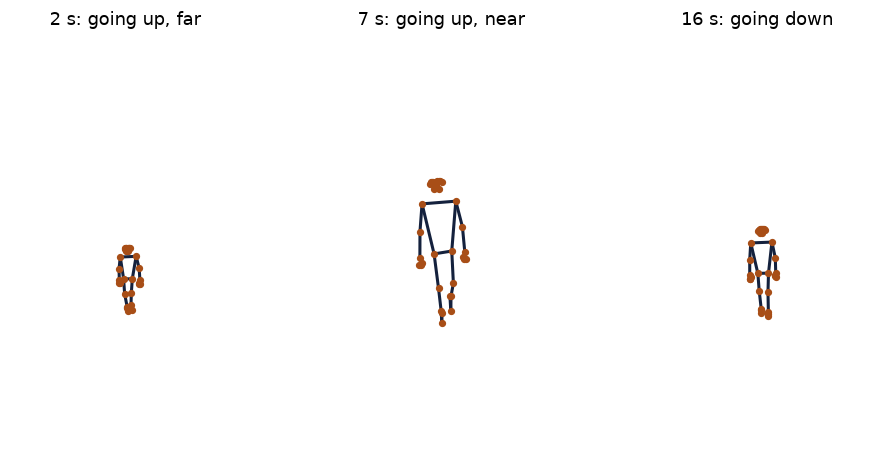

In [6]:
kp_file = "data/video/keypoints/p1_stairs_05.npz"
EDGES = [(11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (11, 23), (12, 24), (23, 24), (23, 25), (25, 27),
         (24, 26), (26, 28), (27, 29), (28, 30), (29, 31), (30, 32), (27, 31), (28, 32)]
if os.path.exists(kp_file):
    kp = np.load(kp_file)["kp"]
    fig, axes = plt.subplots(1, 3, figsize=(9, 4.2))
    for ax, sec, label in zip(axes, (2, 7, 16), ("going up, far", "going up, near", "going down")):
        P = kp[int(sec * 25), :, :2] * [576, 1024]
        for a, b in EDGES:
            ax.plot(P[[a, b], 0], P[[a, b], 1], color="#14213D", lw=2)
        ax.scatter(P[:, 0], P[:, 1], s=14, color="#A84E17", zorder=3)
        ax.set_title(f"{sec} s: {label}"); ax.set_xlim(0, 576); ax.set_ylim(1024, 0); ax.set_aspect("equal"); ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Our keypoints are not on GitHub (privacy). The saved figure above was made on the laptop.")

In [7]:
import joblib
from video_pose import MODEL, window_features
if os.path.exists(kp_file) and os.path.exists(MODEL):
    bundle = joblib.load(MODEL)
    starts, F = window_features(np.load(kp_file)["kp"], bundle, cfg)
    act, conf = _classify(F, bundle)
    print("clip A (8), one label per 2-second window, every second:")
    print(" ".join(f"{s / 25:.0f}s:{a}" for s, a in zip(starts, act)))
    print("This clip was used in training, so this shows how the pipeline works, not how accurate it is.")
else:
    print("Our body-point files are not on GitHub (privacy). The saved output above was made on the laptop.")

clip A (8), one label per 2-second window, every second:
0s:upstairs 1s:upstairs 2s:upstairs 3s:upstairs 4s:upstairs 5s:upstairs 6s:upstairs 7s:upstairs 8s:upstairs 9s:downstairs 10s:downstairs 11s:downstairs 12s:downstairs 13s:downstairs 14s:downstairs 15s:downstairs 16s:downstairs 17s:downstairs 18s:downstairs
This clip was used in training, so this shows how the pipeline works, not how accurate it is.


In [8]:
pd.DataFrame([
    ("Phone model (1D-CNN)", "9 UCI people never seen", "91.0%", "0.909", "random guessing: 17%"),
    ("Camera model", "each of our 4 people, left out in turn", "64%", "0.65", "random guessing: 0.33 macro F1"),
    ("Stairs direction (up or down)", "each of our 4 people, left out in turn", "85% (side views 80%)", "", "shuffled labels: 50%"),
], columns=["Model", "Tested on", "Accuracy", "Macro F1", "Baseline"])

,Model,Tested on,Accuracy,Macro F1,Baseline
0,Phone model (1D-CNN),9 UCI people never seen,91.0%,0.909,random guessing: 17%
1,Camera model,"each of our 4 people, left out in turn",64%,0.65,random guessing: 0.33 macro F1
2,Stairs direction (up or down),"each of our 4 people, left out in turn",85% (side views 80%),,shuffled labels: 50%
